# Notebook 06 — Cluster Analysis & Product Recommender

**Goal**: Profile each cluster, give them business-meaningful names, and build a product recommendation engine.

**What you'll learn:**
- How to interpret and name clusters (the "so what?" of unsupervised ML)
- Building a rule-based recommender on top of ML output
- Using the full pipeline on new customers

---

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

sns.set_theme(style='whitegrid')

df = pd.read_csv('../data/customers_clustered.csv')
print(f'Loaded {len(df)} clustered customers')
print('Cluster distribution:')
print(df['cluster'].value_counts().sort_index())

Loaded 1000 clustered customers
Cluster distribution:
cluster
0    319
1    192
2    302
3    187
Name: count, dtype: int64


## Step 1 — Profile each cluster

We compute the mean of each feature per cluster.
This tells us: "what does a typical customer in each cluster look like?"

In [2]:
PROFILE_FEATURES = [
    'age', 'annual_income', 'monthly_spending',
    'savings_balance', 'credit_score', 'loan_amount',
    'num_existing_products', 'months_as_customer'
]

cluster_profiles = df.groupby('cluster')[PROFILE_FEATURES].mean().round(0)
print('Cluster Profiles (mean values):')
print(cluster_profiles.T.to_string())

Cluster Profiles (mean values):
cluster                      0         1        2        3
age                       26.0      46.0     42.0     37.0
annual_income          31839.0  118024.0  59020.0  27829.0
monthly_spending        2180.0    5458.0   2622.0   2804.0
savings_balance         2492.0   89017.0  34982.0   1221.0
credit_score             617.0     788.0    732.0    554.0
loan_amount             8117.0   15699.0   6196.0  33520.0
num_existing_products      2.0       5.0      3.0      2.0
months_as_customer        18.0      96.0     73.0     46.0


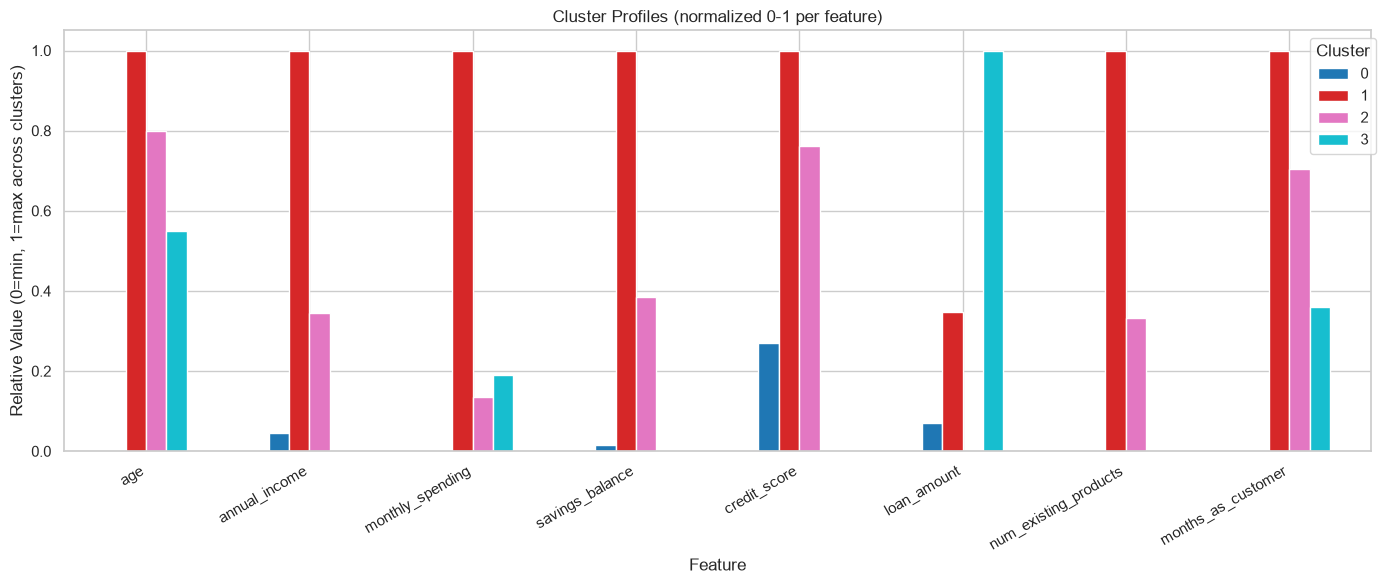

In [3]:
# Visualize profiles as a radar/bar comparison
# Normalize features to 0-1 range for fair comparison on same axis
profiles_norm = (cluster_profiles - cluster_profiles.min()) / (cluster_profiles.max() - cluster_profiles.min())

profiles_norm.T.plot(kind='bar', figsize=(14, 6), colormap='tab10')
plt.title('Cluster Profiles (normalized 0-1 per feature)')
plt.xlabel('Feature')
plt.ylabel('Relative Value (0=min, 1=max across clusters)')
plt.legend(title='Cluster', bbox_to_anchor=(1.01, 1))
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

## Step 2 — Name the clusters

Look at the profile above and give each cluster a business-meaningful name.
This is the most human step in ML — translating numbers into insight.

In [4]:
# We'll assign names based on the dominant characteristics
# Run the profile table above to identify which cluster has what traits

# Automated naming based on profile stats
def name_cluster(row: pd.Series) -> str:
    """
    Assign a name to a cluster based on its mean feature values.
    Uses simple heuristics on income, savings, credit score, and loan amount.
    """
    income   = row['annual_income']
    savings  = row['savings_balance']
    credit   = row['credit_score']
    loan     = row['loan_amount']
    age      = row['age']

    if income > 90_000 and savings > 60_000:
        return 'High Earner'
    elif income < 35_000 and loan > 20_000 and credit < 620:
        return 'Debt Stressed'
    elif savings > 20_000 and credit > 700 and age > 38:
        return 'Stable Saver'
    else:
        return 'Young Spender'

cluster_names = {c: name_cluster(cluster_profiles.loc[c]) for c in cluster_profiles.index}
print('Cluster assignments:')
for cluster_id, name in cluster_names.items():
    dominant_archetype = df[df['cluster'] == cluster_id]['archetype'].value_counts().idxmax()
    print(f'  Cluster {cluster_id} → "{name}"  (true dominant: {dominant_archetype})')

Cluster assignments:
  Cluster 0 → "Young Spender"  (true dominant: young_spender)
  Cluster 1 → "High Earner"  (true dominant: high_earner)
  Cluster 2 → "Stable Saver"  (true dominant: stable_saver)
  Cluster 3 → "Debt Stressed"  (true dominant: debt_stressed)


In [5]:
# Add segment name to the DataFrame
df['segment'] = df['cluster'].map(cluster_names)
print('Segment distribution:')
print(df['segment'].value_counts())

Segment distribution:
segment
Young Spender    319
Stable Saver     302
High Earner      192
Debt Stressed    187
Name: count, dtype: int64


## Step 3 — Product Recommendation Logic

Now that we know which segment each customer belongs to, we can recommend the right product.

| Segment | Recommended Product | Reasoning |
|---|---|---|
| Young Spender | Premium Cashback Credit Card | High spending, wants rewards |
| Stable Saver | High-Yield Savings Account | Already saving, wants growth |
| High Earner | Investment Portfolio / Wealth Management | High income and savings, ready to invest |
| Debt Stressed | Debt Consolidation Loan | Reduce interest burden |

This is a **rule-based recommender** — the rules come from business knowledge, the clusters come from ML. Together they're powerful.

In [6]:
PRODUCT_MAP = {
    'Young Spender': {
        'product': 'Premium Cashback Credit Card',
        'pitch': 'Earn up to 5% cashback on every transaction. No annual fee for the first year.',
        'upsell': 'Starter Savings Plan — build your emergency fund while you spend smart.'
    },
    'Stable Saver': {
        'product': 'High-Yield Savings Account',
        'pitch': 'Earn 4.8% APY on your savings, with no minimum balance requirement.',
        'upsell': 'Fixed Deposit — lock in a higher rate for 12-24 months.'
    },
    'High Earner': {
        'product': 'Wealth Management Portfolio',
        'pitch': 'Personalized investment strategy with a dedicated advisor. Minimum £50k.',
        'upsell': 'Private Banking Suite — exclusive benefits, priority service, travel perks.'
    },
    'Debt Stressed': {
        'product': 'Debt Consolidation Loan',
        'pitch': 'Combine your debts into one low-rate monthly payment. Up to 60-month terms.',
        'upsell': 'Free Financial Health Check with our advisors.'
    },
}

def recommend(segment: str) -> dict:
    return PRODUCT_MAP.get(segment, {'product': 'General Banking Package', 'pitch': 'Contact us to discuss your options.', 'upsell': ''})

# Apply to all customers
df['recommended_product'] = df['segment'].apply(lambda s: recommend(s)['product'])
df['pitch']               = df['segment'].apply(lambda s: recommend(s)['pitch'])

print('Sample recommendations:')
df[['customer_id', 'segment', 'recommended_product']].groupby('segment').head(2)

Sample recommendations:


,customer_id,segment,recommended_product
0,C00001,High Earner,Wealth Management Portfolio
1,C00002,Stable Saver,High-Yield Savings Account
2,C00003,Debt Stressed,Debt Consolidation Loan
3,C00004,High Earner,Wealth Management Portfolio
4,C00005,Young Spender,Premium Cashback Credit Card
5,C00006,Debt Stressed,Debt Consolidation Loan
8,C00009,Young Spender,Premium Cashback Credit Card
9,C00010,Stable Saver,High-Yield Savings Account


Product recommendation distribution:
recommended_product
Premium Cashback Credit Card    319
High-Yield Savings Account      302
Wealth Management Portfolio     192
Debt Consolidation Loan         187
Name: count, dtype: int64


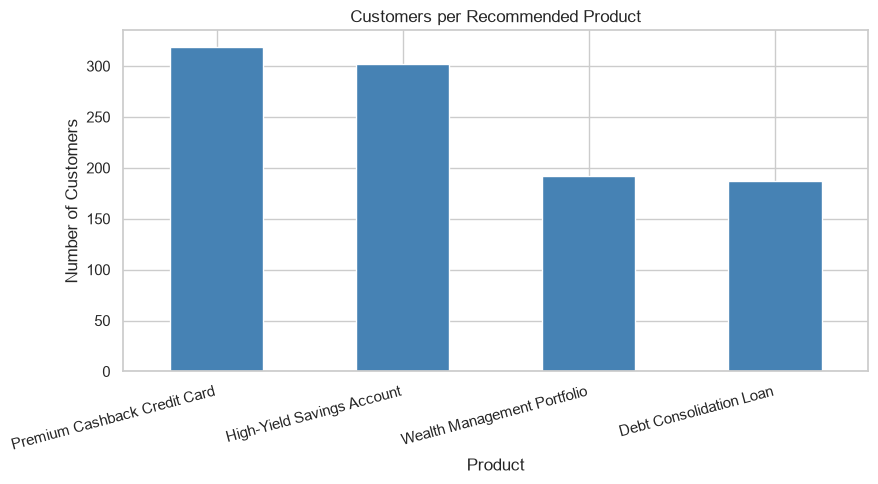

In [7]:
# Summary: how many customers get each recommendation
print('Product recommendation distribution:')
print(df['recommended_product'].value_counts())

plt.figure(figsize=(9, 5))
df['recommended_product'].value_counts().plot(kind='bar', color='steelblue', edgecolor='white')
plt.title('Customers per Recommended Product')
plt.xlabel('Product')
plt.ylabel('Number of Customers')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

## Step 4 — Full Pipeline: Recommend for a New Customer

Now let's tie everything together. Given a new customer's raw data, we:
1. Preprocess (impute + scale)
2. Apply PCA
3. Predict cluster with KMeans
4. Map to segment name
5. Recommend a product

In [8]:
# Load saved models
preprocessing_pipeline = joblib.load('../data/preprocessing_pipeline.pkl')
pca_model              = joblib.load('../data/pca_model.pkl')
kmeans_model           = joblib.load('../data/kmeans_model.pkl')

FEATURES = [
    'age', 'annual_income', 'monthly_spending', 'savings_balance',
    'credit_score', 'loan_amount', 'num_existing_products',
    'months_as_customer', 'spending_ratio', 'savings_ratio'
]

def predict_segment_and_recommend(customer: dict) -> dict:
    """
    Given a raw customer dict, return segment name and product recommendation.
    """
    # Step 1: build a 1-row DataFrame
    row = pd.DataFrame([customer])

    # Step 2: add engineered features
    row['spending_ratio'] = row['monthly_spending'] / (row['annual_income'] / 12)
    row['savings_ratio']  = row['savings_balance'] / row['annual_income']

    # Step 3: preprocess (impute + scale)
    X_preprocessed = preprocessing_pipeline.transform(row[FEATURES])

    # Step 4: PCA
    X_pca = pca_model.transform(X_preprocessed)

    # Step 5: cluster prediction
    cluster_id = kmeans_model.predict(X_pca)[0]

    # Step 6: name + recommend
    segment = cluster_names[cluster_id]
    rec     = recommend(segment)

    return {
        'cluster': cluster_id,
        'segment': segment,
        'recommended_product': rec['product'],
        'pitch': rec['pitch'],
        'upsell': rec['upsell'],
    }


# Test with example customers
example_customers = [
    {
        'name': 'Alice (young, high spender)',
        'age': 24, 'annual_income': 31000, 'monthly_spending': 2400,
        'savings_balance': 1800, 'credit_score': 605, 'loan_amount': 7000,
        'num_existing_products': 1, 'months_as_customer': 12
    },
    {
        'name': 'Bob (mid-career, good saver)',
        'age': 44, 'annual_income': 62000, 'monthly_spending': 2600,
        'savings_balance': 38000, 'credit_score': 740, 'loan_amount': 4000,
        'num_existing_products': 3, 'months_as_customer': 84
    },
    {
        'name': 'Carol (high earner)',
        'age': 51, 'annual_income': 145000, 'monthly_spending': 6000,
        'savings_balance': 110000, 'credit_score': 800, 'loan_amount': 12000,
        'num_existing_products': 5, 'months_as_customer': 120
    },
    {
        'name': 'David (debt stressed)',
        'age': 36, 'annual_income': 27000, 'monthly_spending': 2900,
        'savings_balance': 900, 'credit_score': 540, 'loan_amount': 36000,
        'num_existing_products': 1, 'months_as_customer': 36
    },
]

print('=' * 60)
for customer in example_customers:
    name = customer.pop('name')
    result = predict_segment_and_recommend(customer)
    print(f'Customer: {name}')
    print(f'  Segment:   {result["segment"]}')
    print(f'  Product:   {result["recommended_product"]}')
    print(f'  Pitch:     {result["pitch"]}')
    print(f'  Upsell:    {result["upsell"]}')
    print()

Customer: Alice (young, high spender)
  Segment:   Young Spender
  Product:   Premium Cashback Credit Card
  Pitch:     Earn up to 5% cashback on every transaction. No annual fee for the first year.
  Upsell:    Starter Savings Plan — build your emergency fund while you spend smart.

Customer: Bob (mid-career, good saver)
  Segment:   Stable Saver
  Product:   High-Yield Savings Account
  Pitch:     Earn 4.8% APY on your savings, with no minimum balance requirement.
  Upsell:    Fixed Deposit — lock in a higher rate for 12-24 months.

Customer: Carol (high earner)
  Segment:   High Earner
  Product:   Wealth Management Portfolio
  Pitch:     Personalized investment strategy with a dedicated advisor. Minimum £50k.
  Upsell:    Private Banking Suite — exclusive benefits, priority service, travel perks.

Customer: David (debt stressed)
  Segment:   Debt Stressed
  Product:   Debt Consolidation Loan
  Pitch:     Combine your debts into one low-rate monthly payment. Up to 60-month terms.
  

/Users/tanviagarwal/Documents/Projects/banksense/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
/Users/tanviagarwal/Documents/Projects/banksense/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
/Users/tanviagarwal/Documents/Projects/banksense/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(
/Users/tanviagarwal/Documents/Projects/banksense/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


## Final Summary — What you built

```
Raw customer data
       ↓
  EDA (understand the data)
       ↓
  Preprocessing (impute + scale)
       ↓
  PCA (reduce 10 features → few components)
       ↓
  KMeans clustering (find 4 natural groups)
       ↓
  Cluster analysis (name each group)
       ↓
  Product recommendation (ML output → business action)
```

## Full concept checklist

| Concept | Covered |
|---|---|
| pandas DataFrames | ✅ Notebook 01 |
| EDA + visualization | ✅ Notebook 02 |
| Missing value imputation | ✅ Notebook 03 |
| Feature scaling | ✅ Notebook 03 |
| sklearn Pipeline | ✅ Notebook 03 |
| Data leakage | ✅ Notebook 03 |
| PCA | ✅ Notebook 04 |
| Explained variance | ✅ Notebook 04 |
| KMeans | ✅ Notebook 05 |
| Elbow method | ✅ Notebook 05 |
| Silhouette score | ✅ Notebook 05 |
| Cluster profiling | ✅ Notebook 06 |
| Feature engineering | ✅ Notebooks 01 + 06 |
| Model persistence (joblib) | ✅ Notebooks 03-06 |
| Production pipeline | ✅ Notebook 06 |

**Where to go next:**
- Add a supervised classifier (predict segment from features, without clustering)
- Try DBSCAN or Gaussian Mixture Models as alternative clustering algorithms
- Build a simple Flask/FastAPI endpoint that wraps `predict_segment_and_recommend`